## 1. Getting Started
At first you should install reuirements using `requirements.txt` file. After That you need to clone the files in `alignOT` folter and put it in the same folder as your code. Commands for this step are included in the `README` as well. After that you should import `utils.py` file.

In [11]:
from utils import *

%matplotlib inline
plt.rcParams["figure.figsize"] = (7,5)

## 2. Load The Maps
After that you should load and sample the maps.

In [12]:
input_mrc = '../../Data/0.1/Cluster_0/0.mrc'

with mrcfile.open(input_mrc, permissive=True) as mrc:
    vol = mrc.data.astype(np.float32)

# Step 1: shift to positive
vol = vol - vol.min()

# Step 2: scale to [0, 1]
vol = vol / (vol.max() + 1e-8)
vol_dark = 1.0 - vol

# Threshold and sample
map_th = vol_dark.copy()
thresh = 0.7
M = 500
map_th[map_th < thresh] = 0

rm0, arr_flat, arr_idx, xyz, coords_1d = trn.trn_rm0(map_th, M, random_seed=42)
l0 = 0.005 * M
lf = 0.5
tf = M * 8
e0 = 0.3
ef = 0.05
rms, rs, ts_save = trn.trn_iterate(rm0, arr_flat, arr_idx, xyz, n_save=10, e0=e0, ef=ef, l0=l0, lf=lf, tf=tf, do_log=True, log_n=10)

x = [p[0] for p in rms[10]]
y = [p[1] for p in rms[10]]
z = [p[2] for p in rms[10]]


(92, 92, 92)
0
400
800
1200
1600
2000
2400
2800
3200
3600


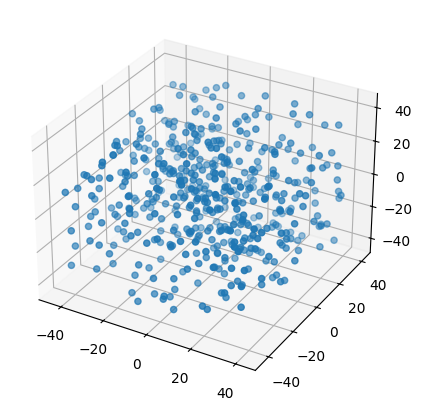

In [13]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(x, y, z,  marker='o')
plt.show()

Do the same for the second map.

In [14]:
xr, yr, zr = perform(x, y, z, get_quaternion_vals(30 * math.pi /180, 0, 1, 0))

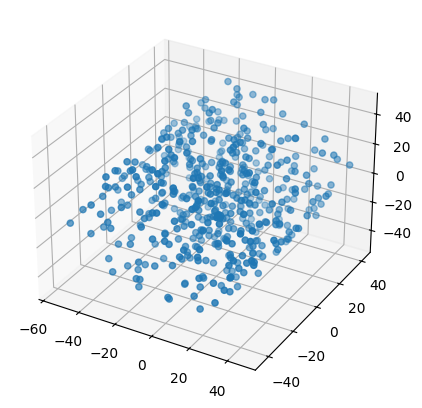

In [15]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(xr, yr, zr,  marker='o')
plt.show()

## 3. Run alignOT
In the next step you should run `alignOT` on the prepared data.

In [16]:
quartenions, costs = SGD(x, y, z, xr, yr, zr, lr=0.00001, max_iter=1000, reg=30, num_samples=1, verbose=True)

Iteration number 9, the wasserstein deistance is 76.00
Iteration number 19, the wasserstein deistance is 77.51
Iteration number 29, the wasserstein deistance is 78.37
Iteration number 39, the wasserstein deistance is 78.22
Iteration number 49, the wasserstein deistance is 78.05
Iteration number 59, the wasserstein deistance is 76.56
Iteration number 69, the wasserstein deistance is 76.59
Iteration number 79, the wasserstein deistance is 76.24
Iteration number 89, the wasserstein deistance is 78.31
Iteration number 99, the wasserstein deistance is 77.58
Iteration number 109, the wasserstein deistance is 78.95
Iteration number 119, the wasserstein deistance is 78.50
Iteration number 129, the wasserstein deistance is 78.32
Iteration number 139, the wasserstein deistance is 77.19
Iteration number 149, the wasserstein deistance is 76.42
Iteration number 159, the wasserstein deistance is 75.88
Iteration number 169, the wasserstein deistance is 76.87
Iteration number 179, the wasserstein deis

## 4. Analyze The Outputs

The final found quaternion is:
[np.float64(0.9659258262890684), np.float64(-7.41131818997041e-18), np.float64(0.25881904510252063), np.float64(7.517123498700954e-18)]
The ideal quaternion is:
[0.9659258262890683, 0.0, 0.1830127018922193, 0.1830127018922193]
The angle difference is 0.00 degree(s).


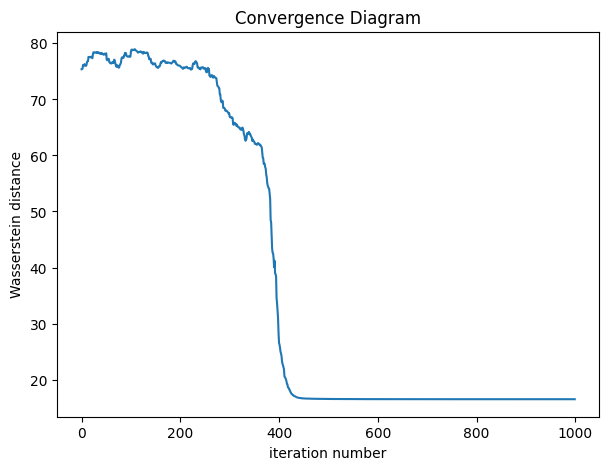

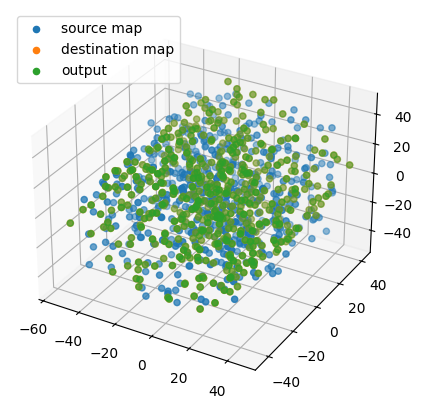

In [17]:
print("The final found quaternion is:")
print(quartenions[-1])
print("The ideal quaternion is:")
print(get_quaternion_vals(math.pi/6, 0, 1, 1))
print("The angle difference is %0.2f degree(s)."%(diff_quaternions(quartenions[-1], get_quaternion_vals(math.pi/6, 0, 1, 0)),))


fig, ax = plt.subplots()
plt.title('Convergence Diagram')
plt.xlabel('iteration number')
plt.ylabel('Wasserstein distance')
plt.plot(costs)
plt.show()

x_fin, y_fin, z_fin = perform(x, y, z, quartenions[-1])

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(x, y, z, c='C0',  marker='o', label='source map')
ax.scatter(xr, yr, zr, c='C1', marker='o', label='destination map')
ax.scatter(x_fin, y_fin, z_fin, c='C2',  marker='o', label='output')
plt.legend()
plt.show()